# Experiment 18: Final model against the untuned MLP and the baseline

Card: [exp18_final_comparison.md](../../experiments/exp18_final_comparison.md)


In [1]:
import os
import sys

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS, MLFLOW_URI
from ashrae.plots import INK, SURFACE, TEXT, style_axis
from ashrae.tracking import session_runs

SMOKE = os.environ.get("SMOKE") == "1"
THRESHOLD = 0.01
if SMOKE:
    FOLD_NAMES = list(FOLDS)[:1]  # the exp17 smoke run trained one fold
    # name: (experiment, session, tag filter); None: the latest session
    MODELS = {
        "final": ("ashrae-mlp-lr-schedule-smoke", None, {"schedule": "step"}),
        "mlp_4out_emb before tuning": (
            "ashrae-mlp-building-smoke",
            None,
            {"model": "mlp_4out_emb"},
        ),
        "lgbm_building": (
            "ashrae-baseline-building-smoke",
            None,
            {"model": "lgbm_building"},
        ),
    }
    FIGURE = None
else:
    FOLD_NAMES = list(FOLDS)
    MODELS = {
        "final": (
            "ashrae-mlp-lr-schedule",
            "2026-10-13 10:29:04",
            {"schedule": "step"},
        ),  # exp17
        "mlp_4out_emb before tuning": (
            "ashrae-mlp-building",
            "2026-10-12 12:03:22",
            {"model": "mlp_4out_emb"},
        ),  # exp02
        "lgbm_building": (
            "ashrae-baseline-building",
            "2026-10-11 11:16:15",
            {"model": "lgbm_building"},
        ),  # baseline exp01
    }
    FIGURE = "../../figures/exp18_final_comparison.png"

mlflow.set_tracking_uri(MLFLOW_URI)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Results


In [2]:
# MLflow keeps each metric's last logged value: the last epoch of an MLP, the only value of LightGBM
results = pd.concat(
    session_runs(name, session, **tags).assign(model=model)
    for model, (name, session, tags) in MODELS.items()
)[
    [
        "model",
        "fold",
        "metrics.val_rmsle",
        "metrics.val_rmsle_clean",
        "metrics.train_rmsle",
    ]
]
results.columns = ["model", "fold", "val", "val_clean", "train"]
results = results[results.fold.isin(FOLD_NAMES)]

table = {}
for key in ["val", "val_clean", "train"]:
    t = results.pivot_table(index="model", columns="fold", values=key)[FOLD_NAMES]
    t["average"] = t.mean(axis=1)
    table[key] = t.loc[list(MODELS)]
display(
    pd.concat(table, names=["metric"])
    .round(3)
    .rename_axis(columns="RMSLE at the last epoch")
)

gain = table["val"].drop("final") - table["val"].loc["final"]
print(f"folds where the final model is more than {THRESHOLD} lower (all rows):")
for model, row in gain.iterrows():
    folds = (row[FOLD_NAMES] > THRESHOLD).sum()
    print(
        f"  vs {model}: {folds} of {len(FOLD_NAMES)}, average gain {row['average']:.3f}"
    )

RMSLE at the last epoch               Jan–Mar  Apr–Jun  Jul–Sep  Oct–Dec  \
metric    model                                                            
val       final                         1.392    1.194    1.007    1.085   
          mlp_4out_emb before tuning    1.420    1.223    1.053    1.105   
          lgbm_building                 1.434    1.231    1.087    1.116   
val_clean final                         0.899    0.868    0.865    0.997   
          mlp_4out_emb before tuning    0.921    0.889    0.911    1.016   
          lgbm_building                 0.951    0.909    0.952    1.024   
train     final                         0.816    0.807    0.821    0.770   
          mlp_4out_emb before tuning    0.839    0.830    0.843    0.791   
          lgbm_building                 0.825    0.822    0.829    0.783   

RMSLE at the last epoch               average  
metric    model                                
val       final                         1.170  
          mlp_4out_emb before tuning    1.200  
          lgbm_building                 1.217  
val_clean final                         0.907  
          mlp_4out_emb before tuning    0.934  
          lgbm_building                 0.959  
train     final                         0.803  
          mlp_4out_emb before tuning    0.826  
          lgbm_building                 0.815

folds where the final model is more than 0.01 lower (all rows):
  vs mlp_4out_emb before tuning: 4 of 4, average gain 0.031
  vs lgbm_building: 4 of 4, average gain 0.048


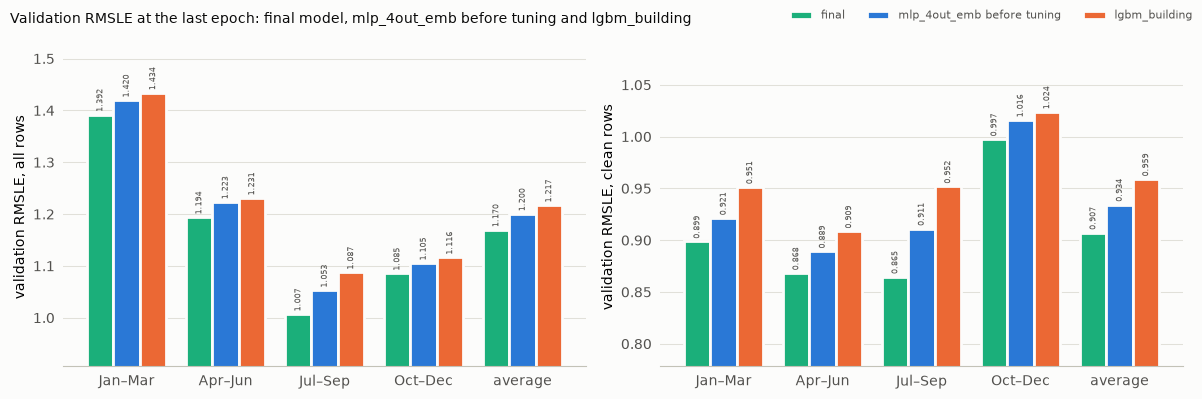

In [3]:
# first three categorical slots of the dataviz palette, colorblind-safe for any pair; final keeps its report color
COLORS = {
    "final": "#1baf7a",  # aqua
    "mlp_4out_emb before tuning": "#2a78d6",  # blue
    "lgbm_building": "#eb6834",  # orange
}

columns = [*FOLD_NAMES, "average"]
x = np.arange(len(columns))
bar = 0.8 / len(MODELS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor=SURFACE)
for ax, (key, label) in zip(
    axes,
    [
        ("val", "validation RMSLE, all rows"),
        ("val_clean", "validation RMSLE, clean rows"),
    ],
):
    t = table[key]
    for i, model in enumerate(MODELS):
        values = t.loc[model, columns]
        bars = ax.bar(
            x + (i - (len(MODELS) - 1) / 2) * bar,
            values,
            bar,
            color=COLORS[model],
            edgecolor=SURFACE,  # 2px surface gap between adjacent bars
            linewidth=2,
            label=model,
        )
        ax.bar_label(bars, fmt="%.3f", fontsize=6, color=TEXT, padding=2, rotation=90)
    lo = t[columns].min().min()
    ax.set_ylim(
        lo * 0.9, t[columns].max().max() * 1.06
    )  # zoom in: the gaps are small against the level
    ax.set_xticks(x, columns)
    ax.set(ylabel=label)
    style_axis(ax)
fig.legend(
    *axes[0].get_legend_handles_labels(),
    frameon=False,
    fontsize=8,
    labelcolor=TEXT,
    loc="upper right",
    ncol=len(MODELS),
)
fig.suptitle(
    "Validation RMSLE at the last epoch: final model, mlp_4out_emb before tuning and lgbm_building",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
)
fig.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")